# **고객의도 분류하기**

고객의 질문을 보고 어떤 의도로 물어본 것인지 10개의 라벨 중 하나로 분류하는 미니프로젝트

```
ex)
이거 카드 결제 되나요?        > 결제
주말에도 문 여나요?           > 시간
제일 잘 나가는 메뉴가 뭐예요?  > 추천
```

In [47]:
import pandas as pd
import numpy as np
import random
import time
import datetime
import torch
import warnings
import matplotlib.pyplot as plt

import torch
from pathlib import Path
from torch.optim import AdamW
from torch.utils.data import TensorDataset, DataLoader, RandomSampler, SequentialSampler
from transformers import pipeline
from transformers import AutoTokenizer
from transformers import AutoModelForSequenceClassification
from transformers import get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")
plt.rcParams["font.family"] = "Malgun Gothic"

In [2]:
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print("DEVICE:", DEVICE)

DEVICE: cuda


In [3]:
DATA_DIR = Path("./data")

# 파일이 두 개의 구조로 나뉘어져 있어, SHOPS와 CIVILS로 나누어 관리

SHOPS = {
    "음식점": "A 음식점(15,726)_new.xlsx",
    "의류": "B 의류(15,826)_new.xlsx",
    "학원": "C 학원(4,773)_new.xlsx",
    "소매점": "D 소매점(14,949)_new.xlsx",
    "생활서비스": "E 생활서비스(11,087)_new.xlsx",
    "카페": "F 카페(7,859)_new.xlsx",
    "숙박업": "G 숙박업(7,113)_new.xlsx",
    "관광여가오락": "H 관광여가오락(4,949)_new.xlsx",
    "부동산": "I 부동산(8,131)_new.xlsx",
}

CIVILS = {
    "교통": "j 교통_최종본(250814).xlsx",
    "상수도": "k 상수도_최종본(250814).xlsx",
    "여권": "l 여권 최종본(250814).xlsx",
    "차량등록": "m 차량등록_최종본(250814).xlsx",
}

In [4]:
raw = pd.read_excel(DATA_DIR / SHOPS["음식점"])
print(raw.shape)
raw.head()

(15726, 18)


,SPEAKER,SENTENCE,DOMAINID,DOMAIN,CATEGORY,SPEAKERID,SENTENCEID,MAIN,SUB,QA,QACNCT,MQ,SQ,UA,SA,개체명,용어사전,지식베이스
0,고객,지금 배달되나요?,A,음식점,배달음식점,1,1,배달가능문의,NaN,Q,NaN,지금 배달되나요?,NaN,NaN,NaN,"수고, 지금, 배달",NaN,NaN
1,점원,아 네 배달됩니다,A,음식점,배달음식점,0,2,배달가능문의,NaN,A,NaN,NaN,NaN,NaN,아 네 배달됩니다,배달,NaN,NaN
2,고객,짬뽕류는 어떤 게 있나요? 잘 나가는 짬뽕 있나요?,A,음식점,배달음식점,1,3,베스트메뉴문의추천요청,NaN,Q,NaN,짬뽕류는 어떤 게 있나요? 잘 나가는 짬뽕 있나요?,NaN,NaN,NaN,짬뽕,NaN,짬뽕/메뉴
3,점원,특해물 짬뽕도 있고 전복 새우 짬뽕도 있고 해물 종류도 새우 홍합 전복 없는 게 없습니다,A,음식점,배달음식점,0,4,베스트메뉴문의추천요청,NaN,A,NaN,NaN,NaN,NaN,특해물 짬뽕도 있고 전복 새우 짬뽕도 있고 해물 종류도 새우 홍합 전복 없는 게 없습니다,"특해물 짬뽕, 전복 새우 짬뽕, 해물 종류, 새우, 홍합, 전복",NaN,"특해물 짬뽕/메뉴, 전복 새우 짬뽕/메뉴, 새우/해물/재료, 홍합/해물/재료, 전복..."
4,고객,전복 들어가는 거는 특해물 짬뽕 시켜야 돼요?,A,음식점,배달음식점,1,5,메뉴정보문의,NaN,Q,NaN,전복 들어가는 거는 특해물 짬뽕 시켜야 돼요?,NaN,NaN,NaN,"전복, 특해물 짬뽕",NaN,"전복/해물/재료, 특해물 짬뽕/메뉴"


In [5]:
raw_civil = pd.read_excel(DATA_DIR / CIVILS["교통"])
print(raw_civil.shape)
raw_civil.head()

(667, 10)


,도메인,화자,intent,subintent,question,비식별 데이터,q_entity,a_entity,용어사전,지식베이스
0,교통,민원인,길찾기,NaN,#출발지# 앞에서 #도착지#가는 버스있나요,#출발지# 앞에서요 #버스번호# 그리고 #버스번호# #버스번호# 탑승하시면은 환...,"#출발지# 앞, #도착지#, 버스,","#출발지# 앞, #버스번호#, #버스번호#, #버스번호#, 탑승, #위치#","#도착지#/#도착지#, 탑승/승차","#출발지# 앞/출발지/위치,#도착지#/도착지/위치,"
1,교통,민원인,분실물,NaN,분실물 때문에 전화드렸는데요,택시회사로 한번 확인을 해 보셔야 될 것 같구요 제가 택시회사번호를 좀 알려드릴까요,분실물,"택시회사, 택시, 회사번호","분실물/분실물, 회사번호/회사번호",NaN
2,교통,상담사,분실물,분실물,어떤 물품이요 선생님,가방에 안에다가 지갑을 넣었는데 가방을 놓고 내렸는 것 같아가지고,물품,"가방, 지갑",NaN,"가방/분실물/분실물,"
3,교통,상담사,분실물,대중교통수단,버스에서 말씀이십니까?,택시요,버스,택시,NaN,"버스/대중교통수단/교통수단,택시/대중교통수단/교통수단,"
4,교통,상담사,분실물,시간,언제 그러신 거세요 선생님,#시간#요 #시간# 쯤요,NaN,"일월, 일일, 새벽, 여섯시",NaN,"일월 일일 새벽 여섯시/시간/시간,"


## 데이터 정제
### 1. 엑설 구조가 두 종류로 나뉨
- 소상공인 파일: SPEAKER(고객/점원), SENTENCE(문장), MAIN(의도), QA(질문 Q / 대답 A) 등 18개 열
- 민원 파일: 화자(민원인/상담사), intent(의도), question(질문), 비식별 데이터(대답) 등 10개 열
- 민원 파일끼리도 열 이름이 조금씩 다름 (차량등록은 첫 열 이름이 깨져 있고 intent 대신 main)

In [6]:
for domain, file_name in CIVILS.items():
    df = pd.read_excel(DATA_DIR / file_name)
    print(f"{domain} :", df.columns.tolist()[:5])

교통 : ['도메인', '화자', 'intent', 'subintent', 'question']
상수도 : ['도메인', '화자', 'intent', 'subintent', 'question']
여권 : ['도메인', '화자', 'intent', 'subintent', 'question']
차량등록 : ['도메인E33F2804A1:E30A1:E39A1:E45F2804A1:E30A1:E51A1:E...', '화자', 'main', 'subintent', 'question']


- 열 이름 대신 위치로 필요한 열만 꺼내서 domain, text, main 세 개의 열로 통일
- 의도 분류의 대상은 고객이 한 질문이므로
    - 소상공인: SPEAKER == "고객" 이고 QA == "Q" 인 문장만 사용 (점원의 말, 점원 질문에 대한 고객의 대답은 제외)
    - 민원: 화자 == "민원인" 인 질문만 사용

In [7]:
frames = []

for domain, file_name in SHOPS.items():
    df = pd.read_excel(DATA_DIR / file_name)

    # 고객이 한 질문만 남김
    df = df[(df["SPEAKER"] == "고객") & (df["QA"] == "Q")]
    frames.append(pd.DataFrame({"domain": domain, "text": df["SENTENCE"], "main": df["MAIN"]}))

for domain, file_name in CIVILS.items():
    df = pd.read_excel(DATA_DIR / file_name)
    
    # 열 이름이 파일마다 달라서 위치로 꺼냄 (1: 화자, 2: 의도, 4: 질문)
    df = df[df.iloc[:, 1] == "민원인"]
    frames.append(pd.DataFrame({"domain": domain, "text": df.iloc[:, 4], "main": df.iloc[:, 2]}))

df_copy = pd.concat(frames, ignore_index=True)
print(df_copy.shape)
df_copy.head(10)

(46771, 3)


,domain,text,main
0,음식점,지금 배달되나요?,배달가능문의
1,음식점,짬뽕류는 어떤 게 있나요? 잘 나가는 짬뽕 있나요?,베스트메뉴문의추천요청
2,음식점,전복 들어가는 거는 특해물 짬뽕 시켜야 돼요?,메뉴정보문의
3,음식점,전복 들어가고 여러 가지 또 딴 것도 들어가죠?,메뉴정보문의
4,음식점,마차이 짬뽕밥은 돼지고기 들어가나요?,메뉴정보문의
5,음식점,여기 #주소#인데 배달되나요?,배달장소범위문의
6,음식점,중국집 명성루죠? 배달 지금 가능한가요?,배달가능문의
7,음식점,주로 어떤 게 잘 나가요?,베스트메뉴문의추천요청
8,음식점,4인이 먹을 수 있을까요?,양에대한질문
9,음식점,중자는 얼마에요?,가격문의


In [8]:
df_copy["domain"].value_counts()

domain
의류        7570
음식점       7442
소매점       7242
생활서비스     6073
부동산       4043
카페        3738
숙박업       3137
관광여가오락    2469
학원        2462
차량등록      1666
교통         353
상수도        303
여권         273
Name: count, dtype: int64

### 2. NaN값 제거

In [9]:
df_copy.isna().sum()

domain     0
text       1
main      29
dtype: int64

In [10]:
df_copy[df_copy.isna().any(axis=1)]

,domain,text,main
5055,음식점,2살 아이도 입장 할 수있나요?,NaN
5243,음식점,여기요,NaN
5247,음식점,빨리주세요,NaN
6075,음식점,네 그럼 내일 다시 주문하겠습니다,NaN
6164,음식점,그럼 다음에 주문할게요,NaN
6166,음식점,왜요?,NaN
6214,음식점,어떻게 아셨어요?,NaN
6383,음식점,맛있게 해주세요,NaN
10594,의류,네 이렇게요?,NaN
10664,의류,그럼 다음에 살게요,NaN


문장이나 의도가 비어 있으면 학습에 쓸 수 없으므로 해당 행을 삭제

In [11]:
df_copy = df_copy.dropna().reset_index(drop=True)
df_copy["text"] = df_copy["text"].astype(str).str.strip()
df_copy["main"] = df_copy["main"].astype(str).str.strip()
print(df_copy.shape)
df_copy.isna().sum()

(46741, 3)


domain    0
text      0
main      0
dtype: int64

### 3. 의도 라벨 정리
라벨 종류가 너무 많아 큰 카테고리별로 묶음

In [12]:
print("의도 라벨 종류:", df_copy["main"].nunique())
df_copy["main"].value_counts().head(20)

의도 라벨 종류: 2607


main
가격 문의            1442
메뉴문의              946
제품가격문의            908
가격문의              732
예약문의              552
일반주문              536
구비서류              498
식사주문              381
결제요청              285
메뉴판에있는음식에대한질문     223
제품 문의             201
제품별색깔종류문의         200
영업시간문의            198
요금 문의             197
색상에대한문의           189
결제방식선택            172
종류별의류제품문의요청       158
교육비문의             158
메뉴추천요청            153
할인여부문의            153
Name: count, dtype: int64

In [13]:
df_copy["main"] = df_copy["main"].str.replace(" ", "")
print("의도 라벨 종류:", df_copy["main"].nunique())

price_rows = df_copy[df_copy["main"].str.contains("가격")]
price_rows["main"].value_counts().head(10)

의도 라벨 종류: 2454


main
가격문의         2174
제품가격문의        908
이용가격문의        123
염색가격문의         82
펌가격문의          80
판매단위별가격문의      59
반찬가격문의         47
가격비교           45
커트가격문의         44
가격대별문의         28
Name: count, dtype: int64

In [14]:
INTENT_KEYWORDS = {
    "할인/적립": ["할인", "쿠폰", "적립", "멤버십", "이벤트", "감면", "세일"],
    "결제": ["결제", "영수증", "계산서", "카드", "현금", "계산", "납부", "이체", "환불", "페이", "상품권", "선후불"],
    "가격": ["가격", "요금", "비용", "교육비", "수강료", "시세", "매매가", "임대가", "거래가", "전세가", "금액", "수수료", "얼마", "보증금", "월세", "배달비"],
    "배달/포장": ["배달", "포장", "테이크아웃"],
    "예약": ["예약"],
    "시간": ["시간", "오픈", "마감", "클로징", "휴일", "휴무", "영업일", "영업기간", "체크인", "체크아웃"],
    "위치/시설": ["위치", "주차", "화장실", "시설", "장소", "길찾기", "와이파이", "인터넷", "흡연실", "층문의", "편의", "빈자리", "자리여부", "자리묻기", "자리배치", "원하는자리", "콘센트자리", "게임자리"],
    "추천": ["추천", "베스트", "인기"],
    "주문": ["주문", "구매요청", "고기요청"],
    "상품정보": ["메뉴", "제품", "상품", "색", "사이즈", "치수", "소재", "옷감", "재료", "원산지", "맛", "종류", "용량", "디자인", "재고", "유통기한", "부위", "양에대한", "효과", "기타고기문의", "과일", "면적"],
}
INTENTS = list(INTENT_KEYWORDS.keys())


def to_intent(main):
    for intent in INTENTS:
        for keyword in INTENT_KEYWORDS[intent]:
            if keyword in main:
                return intent
    return None


df_copy["intent"] = df_copy["main"].map(to_intent)
df_copy["intent"].value_counts(dropna=False)

intent
NaN      15399
상품정보      8707
가격        6021
주문        2779
시간        2705
결제        2616
위치/시설     2550
할인/적립     1996
추천        1501
배달/포장     1443
예약        1024
Name: count, dtype: int64

In [15]:
# 새로 추가한 키워드가 어떤 문의를 담고 있는지 확인
AMBIGUOUS_KEYWORDS = ["과일", "고기", "면적", "자리"]


def find_ambiguous(main):
    for keyword in AMBIGUOUS_KEYWORDS:
        if keyword in main:
            return keyword
    return None


ambiguous = df_copy.copy()
ambiguous["keyword"] = ambiguous["main"].map(find_ambiguous)
ambiguous = ambiguous.dropna(subset=["keyword"])
print("애매한 키워드가 들어간 문장 수:", len(ambiguous))

for keyword, group in ambiguous.groupby("keyword"):
    print(f"\n==========={keyword} ({len(group)}문장) ===========")
    print("묶인 의도:", group["intent"].value_counts(dropna=False).to_dict())
    print("업종:", group["domain"].value_counts().to_dict())
    print("원본 라벨:", group["main"].value_counts().head(8).to_dict())
    for text in group["text"].sample(min(5, len(group)), random_state=SEED):
        print("  -", text)

애매한 키워드가 들어간 문장 수: 1061

===========고기 (352문장) ===========
묶인 의도: {'주문': 196, nan: 93, '상품정보': 57, '추천': 3, '가격': 3}
업종: {'소매점': 352}
원본 라벨: {'용도별고기문의': 92, '부위별고기주문': 82, '용도별고기주문': 33, '용량별고기주문': 25, '고기썰기주문': 25, '부위별고기문의': 21, '용도+고기부위문의': 19, '용도+고기부위주문': 9}
  - 소고기 좀 주세요
  - 안심2인분이랑 국거리 조금 주세요.
  - 수육하기 삼겹은 기름기가 너무 많지 않나요?
  - 맛있는 생삼겹살 있나요?
  - 이유식용 소고기 판매하나요?

===========과일 (143문장) ===========
묶인 의도: {'상품정보': 143}
업종: {'소매점': 143}
원본 라벨: {'찾는과일문의': 85, '제철과일나물문의': 33, '과일당도문의': 16, '과일익은상태문의': 5, '손질과일문의': 4}
  - 오늘 귤 없나요?
  - 바나나가 초록색인데 아직 덜 익은거죠?
  - 사과 있나요?
  - 바나나는 없어요?
  - 이 근처에 파인애플 팔 만한 다른 가게는 없어요?

===========면적 (176문장) ===========
묶인 의도: {'상품정보': 176}
업종: {'부동산': 176}
원본 라벨: {'면적문의': 111, '면적별매물문의': 65}
  - 여기 36평 매물 있어요?
  - 열 평은 살림 하기가 좀 그렇죠?
  - 명절에 자식들이 내려와서 편하게 쉴 수 있을 정도의 집에 강아지 두 마리 풀어 놓고 키우려면 어느 정도  돼야 할까요?
  - 크기는 어느 정도인가요?
  - 4인 가족이 살 집을 추천해줄 수 있나요?

===========자리 (390문장) ===========
묶인 의도: {nan: 184, '위치/시설': 176, '예약': 30}
업종: {'음식점': 208, '관광여가오락': 133, '생활

In [16]:
# 의도마다 어떤 원본 라벨이 묶였는지 확인
for intent in INTENTS:
    top = df_copy.loc[df_copy["intent"] == intent, "main"].value_counts().head(6)
    print(f"{intent} :", ", ".join(top.index))

할인/적립 : 할인문의, 할인여부문의, 쿠폰멤버십적립문의, 이벤트문의, 세일기간문의, 할인카드문의
결제 : 결제요청, 결제방식선택, 영수증요청, 결제방법문의, 결제수단문의, 카드결제가능문의
가격 : 가격문의, 제품가격문의, 요금문의, 교육비문의, 이용요금문의, 거래가문의
배달/포장 : 식사배달요청, 배달문의, 배달시간문의, 포장주문문의, 포장주문, 테이크아웃요구
예약 : 예약문의, 예약확인문의, 예약제품도착시간문의, 특정날짜예약문의, 예약자리문의, 재고없을시예약문의
시간 : 영업시간문의, 휴일문의, 오픈시간문의, 소요시간문의, 마감시간문의, 이용시간문의
위치/시설 : 주차문의, 주차공간문의, 장소, 화장실문의, 위치문의, 부대시설이용문의
추천 : 메뉴추천요청, 베스트상품문의, 메뉴추천요구, 제품추천요청, 베스트메뉴문의, 의약품추천요청
주문 : 일반주문, 식사주문, 제품주문, 메뉴주문, 주문가능여부문의, 빵주문


상품정보 : 메뉴문의, 제품문의, 메뉴판에있는음식에대한질문, 제품별색깔종류문의, 색상에대한문의, 원산지문의


In [17]:
# 어떤 의도에도 속하지 않는 라벨 확인
unlabeled = df_copy[df_copy["intent"].isna()]
print("의도에 속하지 않는 라벨 수:", len(unlabeled))
print(len(unlabeled["main"].unique()), "개의 라벨 존재")
unlabeled["main"].value_counts().head(20)

의도에 속하지 않는 라벨 수: 15399
1226 개의 라벨 존재


main
구비서류         498
숙박문의         149
매장에서착용문의     134
수선가능문의       106
과표           106
땅매수문의        101
물요청           96
단순매물문의        96
상담문의          95
이용방법문의        93
용도별고기문의       92
외부음식반입여부      92
복용방법문의        86
서비스문의         84
피팅문의          84
매물나온집보기요청     83
조식제공문의        77
자리문의          75
분실물           74
번호판교체         71
Name: count, dtype: int64

- 특정 업종에서만 나오는 의도
- 의도가 너무 넓어 하나로 정할 수 없는 라벨 전부 제외

In [18]:
# 의도 라벨이 없는 행 제거
df_copy = df_copy.dropna(subset=["intent"]).reset_index(drop=True)
print(df_copy.shape)

(31342, 4)


### 4. 중복 문장 제거

In [19]:
# 1. 문장마다 의도가 몇 종류인지 세기
intent_per_text = df_copy.groupby("text")["intent"].nunique()

# 2. 의도가 2종류 이상인 문장 찾기
conflict_texts = intent_per_text[intent_per_text > 1].index
print("의도가 충돌하는 문장 수:", len(conflict_texts))
df_copy[df_copy["text"].isin(conflict_texts)].sort_values("text").head(12)

의도가 충돌하는 문장 수: 58


,domain,text,main,intent
20590,생활서비스,W약은요?,제품효과문의,상품정보
20594,생활서비스,W약은요?,가격문의,가격
529,음식점,가격이 어떻게 되죠?,베스트메뉴문의추천요청,추천
4989,음식점,가격이 어떻게 되죠?,가격문의,가격
14560,소매점,가격이 어떻게 되죠?,가격문의,가격
9551,의류,그걸로 할게요,가방사이즈에따른제품요청,상품정보
10258,의류,그걸로 할게요,제품주문,주문
22549,카페,그란데 사이즈로 주세요,일반주문,주문
23168,카페,그란데 사이즈로 주세요,사이즈요구,상품정보
24253,카페,그란데 사이즈로 주세요,사이즈요구,상품정보


In [20]:
# 3. 의도가 충돌하는 문장 삭제
df_copy = df_copy[~df_copy["text"].isin(conflict_texts)]

# 4. 같은 문장은 하나만 남기기
print("중복 문장 수:", df_copy["text"].duplicated().sum())
df_copy = df_copy.drop_duplicates(subset="text", keep="first").reset_index(drop=True)

중복 문장 수: 2326


### 5. 의도를 숫자 라벨로 변경

In [63]:
NUM_LABELS = len(INTENTS)

intent2idx = {"할인/적립": 0, "결제": 1, "가격": 2, "배달/포장": 3, "예약": 4,
              "시간": 5, "위치/시설": 6, "추천": 7, "주문": 8, "상품정보": 9}

df_copy["label"] = df_copy["intent"].map(intent2idx).astype(int)
print(intent2idx)
df_copy.head()

{'할인/적립': 0, '결제': 1, '가격': 2, '배달/포장': 3, '예약': 4, '시간': 5, '위치/시설': 6, '추천': 7, '주문': 8, '상품정보': 9}


,domain,text,main,intent,label
0,음식점,지금 배달되나요?,배달가능문의,배달/포장,3
1,음식점,짬뽕류는 어떤 게 있나요? 잘 나가는 짬뽕 있나요?,베스트메뉴문의추천요청,추천,7
2,음식점,전복 들어가는 거는 특해물 짬뽕 시켜야 돼요?,메뉴정보문의,상품정보,9
3,음식점,전복 들어가고 여러 가지 또 딴 것도 들어가죠?,메뉴정보문의,상품정보,9
4,음식점,마차이 짬뽕밥은 돼지고기 들어가나요?,메뉴정보문의,상품정보,9


### 정제 결과

In [22]:
print("최종 문장 수:", len(df_copy))
print("의도 수:", NUM_LABELS)
print(df_copy["intent"].value_counts())

최종 문장 수: 28742
의도 수: 10
intent
상품정보     8474
가격       5318
주문       2596
시간       2331
위치/시설    2317
결제       2032
할인/적립    1929
추천       1447
배달/포장    1321
예약        977
Name: count, dtype: int64


# **Tokenizer를 이용한 데이터 전처리**

In [23]:
# Train, Validation, Test
#   7   :    1.5    : 1.5

train_df, temp_df = train_test_split(df_copy, test_size=0.3, random_state=SEED, stratify=df_copy["label"])
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=SEED, stratify=temp_df["label"])

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train: ", len(train_df))
print("Val: ", len(val_df))
print("Test: ", len(test_df))

Train:  20119
Val:  4311
Test:  4312


In [24]:
MODEL_NAME = "klue/bert-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print("Tokenizer: ", type(tokenizer).__name__)
print("CLS: ", tokenizer.cls_token, tokenizer.cls_token_id)
print("SEP: ", tokenizer.sep_token, tokenizer.sep_token_id)
print("PAD: ", tokenizer.pad_token, tokenizer.pad_token_id)
print("UNK: ", tokenizer.unk_token, tokenizer.unk_token_id)

# MASK 토큰은 의도 분류를 파인튜닝 할 때는 필요 없다.

Tokenizer:  BertTokenizer
CLS:  [CLS] 2
SEP:  [SEP] 3
PAD:  [PAD] 0
UNK:  [UNK] 1


In [25]:
sample_text = train_df["text"][0]
sample = tokenizer(sample_text, add_special_tokens=True, truncation=True, max_length=32, return_tensors='pt', padding='max_length')

print(sample_text)
print(sample['input_ids'])
print(tokenizer.convert_ids_to_tokens(sample['input_ids'][0]))
print(sample['attention_mask'])

학원은 수업료 할인하고 그런 날은 없겠죠?
tensor([[    2,  5266,  2073, 24911,  4986, 19521,  3637,   721,  2073,  1415,
          2918,  2321,    35,     3,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0]])
['[CLS]', '학원', '##은', '수업료', '할인', '##하고', '그런', '날', '##은', '없', '##겠', '##죠', '?', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0]])


In [26]:
MAX_LEN = 128

def encode_texts(texts, labels, tokenizer, max_len=MAX_LEN):
    encoded = tokenizer([str(x) for x in texts],
                        add_special_tokens=True, truncation=True, max_length=max_len,
                        return_tensors='pt', padding='max_length')
    # 한 문장에 정답이 하나인 Multi-class 분류이므로 정답은 정수(long)
    return (encoded['input_ids'], encoded['attention_mask'], torch.tensor(labels, dtype=torch.long))

In [27]:
train_inputs, train_mask, train_labels = encode_texts(train_df["text"].tolist(), train_df["label"].tolist(), tokenizer)
validation_inputs, validation_mask, validation_labels = encode_texts(val_df["text"].tolist(), val_df["label"].tolist(), tokenizer)
test_inputs, test_mask, test_labels = encode_texts(test_df["text"].tolist(), test_df["label"].tolist(), tokenizer)

print("input_ids: ", train_inputs.shape)
print("attention_mask: ", train_mask.shape)
print("labels: ", train_labels.shape)

input_ids:  torch.Size([20119, 128])
attention_mask:  torch.Size([20119, 128])
labels:  torch.Size([20119])


In [28]:
BATCH_SIZE = 32

train_data = TensorDataset(train_inputs, train_mask, train_labels)
validation_data = TensorDataset(validation_inputs, validation_mask, validation_labels)
test_data = TensorDataset(test_inputs, test_mask, test_labels)

# sampler=RandomSampler(train_data) : 학습 데이터의 배치 순서를 랜덤으로 섞어준다.
train_dataloader = DataLoader(train_data, sampler=RandomSampler(train_data), batch_size=BATCH_SIZE)

validation_dataloader = DataLoader(validation_data, sampler=SequentialSampler(validation_data), batch_size=BATCH_SIZE)
test_dataloader = DataLoader(test_data, sampler=SequentialSampler(test_data), batch_size=BATCH_SIZE)

In [29]:
batch = next(iter(train_dataloader))
print("input_ids: ", batch[0].shape)
print("attention_mask: ", batch[1].shape)
print("labels: ", batch[2].shape)

input_ids:  torch.Size([32, 128])
attention_mask:  torch.Size([32, 128])
labels:  torch.Size([32])


# **파인 튜닝**

In [30]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=NUM_LABELS, problem_type="single_label_classification")
model.to(DEVICE)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1426.24it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: klue/bert-base
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint.

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(32000, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,),

In [31]:
print(type(model).__name__)
print(model.config.num_labels)

BertForSequenceClassification
10


In [32]:
EPOCHS = 5
LEARNING_RATE = 2e-5

optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
total_steps = len(train_dataloader) * EPOCHS

scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(total_steps*0.1), num_training_steps=total_steps)
print("전체 학습 step: ", total_steps)

전체 학습 step:  3145


In [33]:
def format_time(elapsed):
    return str(datetime.timedelta(seconds=int(round(elapsed))))


def evaluate(model, dataloader, device):
    model.eval()

    total_loss = 0.0
    all_logits = []
    all_labels = []

    for batch in dataloader:
        input_ids, attention_mask, labels = [x.to(device) for x in batch]

        with torch.inference_mode():
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels,
            )

        total_loss += outputs.loss.item()
        all_logits.append(outputs.logits.cpu())
        all_labels.append(labels.cpu())

    logits = torch.cat(all_logits)
    preds = logits.argmax(dim=1).numpy()
    trues = torch.cat(all_labels).numpy()
    macro_f1 = f1_score(trues, preds, average="macro")

    return total_loss / len(dataloader), macro_f1, preds, trues

In [34]:
MODEL_DIR = Path.cwd() / "model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / "KLUE_BERT_intent.pt"

best_val_f1 = 0.0
history = {"train_loss": [], "val_loss": [], "val_f1": []}

for epoch in range(EPOCHS):
    print(f"\n======== Epoch {epoch + 1} / {EPOCHS} ========")

    start = time.time()
    model.train()
    total_loss = 0.0

    for batch in train_dataloader:
        input_ids, attention_mask, labels = [x.to(DEVICE) for x in batch]

        optimizer.zero_grad(set_to_none=True)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels,
        )

        loss = outputs.loss
        total_loss += loss.item()

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()
        scheduler.step()

    avg_loss = total_loss / len(train_dataloader)

    print(f"Train Loss: {avg_loss:.4f}")
    print("Time:", format_time(time.time() - start))

    val_loss, val_f1, _, _ = evaluate(model, validation_dataloader, DEVICE)
    print(f"Valid Loss: {val_loss:.4f}")
    print(f"Valid Macro F1: {val_f1:.4f}")

    history["train_loss"].append(avg_loss)
    history["val_loss"].append(val_loss)
    history["val_f1"].append(val_f1)

    # Validation Macro F1이 가장 높을 때의 가중치를 저장
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(model.state_dict(), MODEL_PATH)
        print("Best 모델 저장")


======== Epoch 1 / 5 ========
Train Loss: 0.8952
Time: 0:02:19
Valid Loss: 0.4404
Valid Macro F1: 0.8509
Best 모델 저장

======== Epoch 2 / 5 ========
Train Loss: 0.3644
Time: 0:02:20
Valid Loss: 0.3758
Valid Macro F1: 0.8699
Best 모델 저장

======== Epoch 3 / 5 ========
Train Loss: 0.2430
Time: 0:02:24
Valid Loss: 0.3799
Valid Macro F1: 0.8794
Best 모델 저장

======== Epoch 4 / 5 ========
Train Loss: 0.1660
Time: 0:02:22
Valid Loss: 0.4006
Valid Macro F1: 0.8769

======== Epoch 5 / 5 ========
Train Loss: 0.1204
Time: 0:02:21
Valid Loss: 0.4215
Valid Macro F1: 0.8771


# **학습 과정 및 성능 평가**

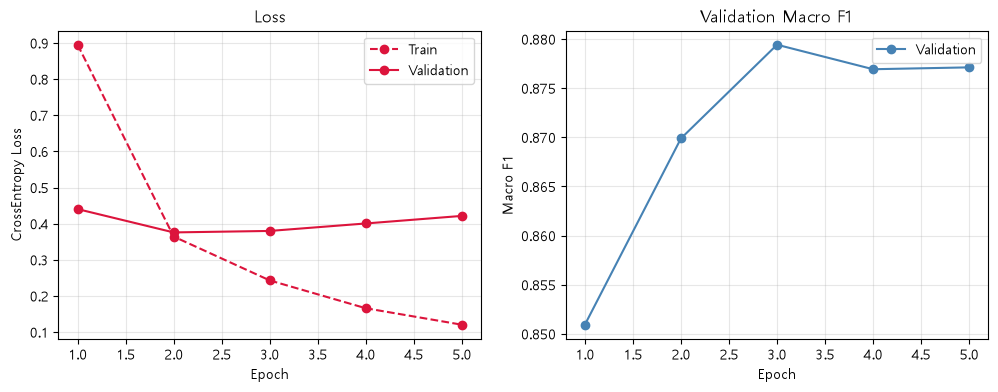

In [49]:
epochs = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history["train_loss"], label="Train", color="crimson", linestyle="--", marker="o")
axes[0].plot(epochs, history["val_loss"], label="Validation", color="crimson", marker="o")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("CrossEntropy Loss")
axes[0].set_title("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history["val_f1"], label="Validation", color="steelblue", marker="o")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro F1")
axes[1].set_title("Validation Macro F1")
axes[1].legend()
axes[1].grid(alpha=0.3)


plt.show()

In [50]:
loaded_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=NUM_LABELS, problem_type="single_label_classification",
)

state_dict = torch.load(MODEL_PATH, map_location="cuda")
loaded_model.load_state_dict(state_dict)
loaded_model.to(DEVICE)
loaded_model.eval()
print("모델 로드 완료")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 975.25it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: klue/bert-base
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. 

모델 로드 완료


In [51]:
_, _, bert_pred, true = evaluate(loaded_model, test_dataloader, DEVICE)

In [52]:
print(f"KLUE-BERT      | Accuracy {accuracy_score(true, bert_pred):.4f} | Macro F1 {f1_score(true, bert_pred, average='macro'):.4f}")

KLUE-BERT      | Accuracy 0.8824 | Macro F1 0.8728


In [53]:
print(classification_report(true, bert_pred, target_names=INTENTS, digits=4))

              precision    recall  f1-score   support

       할인/적립     0.9125    0.9377    0.9249       289
          결제     0.9186    0.9246    0.9216       305
          가격     0.9384    0.9348    0.9366       798
       배달/포장     0.8571    0.8182    0.8372       198
          예약     0.8224    0.8562    0.8389       146
          시간     0.9329    0.9143    0.9235       350
       위치/시설     0.9202    0.8621    0.8902       348
          추천     0.8173    0.7834    0.8000       217
          주문     0.7309    0.8359    0.7799       390
        상품정보     0.8831    0.8678    0.8754      1271

    accuracy                         0.8824      4312
   macro avg     0.8733    0.8735    0.8728      4312
weighted avg     0.8845    0.8824    0.8830      4312



In [54]:
cm = confusion_matrix(true, bert_pred, labels=range(NUM_LABELS), normalize="true")
print("===== KLUE-BERT (실제 의도 기준 비율) =====")
print(pd.DataFrame(cm, index=INTENTS, columns=INTENTS).round(2))

===== KLUE-BERT (실제 의도 기준 비율) =====
       할인/적립    결제    가격  배달/포장    예약    시간  위치/시설    추천    주문  상품정보
할인/적립   0.94  0.01  0.03   0.00  0.00  0.01   0.00  0.00  0.00  0.01
결제      0.02  0.92  0.02   0.00  0.00  0.00   0.00  0.00  0.02  0.01
가격      0.02  0.01  0.93   0.00  0.00  0.00   0.01  0.00  0.00  0.02
배달/포장   0.00  0.01  0.01   0.82  0.01  0.03   0.00  0.00  0.09  0.04
예약      0.00  0.01  0.00   0.03  0.86  0.02   0.03  0.00  0.05  0.01
시간      0.00  0.01  0.00   0.01  0.03  0.91   0.01  0.00  0.01  0.02
위치/시설   0.01  0.01  0.02   0.01  0.02  0.01   0.86  0.00  0.00  0.07
추천      0.00  0.00  0.00   0.00  0.00  0.00   0.01  0.78  0.00  0.20
주문      0.00  0.01  0.01   0.02  0.02  0.00   0.01  0.01  0.84  0.10
상품정보    0.00  0.00  0.02   0.01  0.00  0.01   0.01  0.03  0.06  0.87


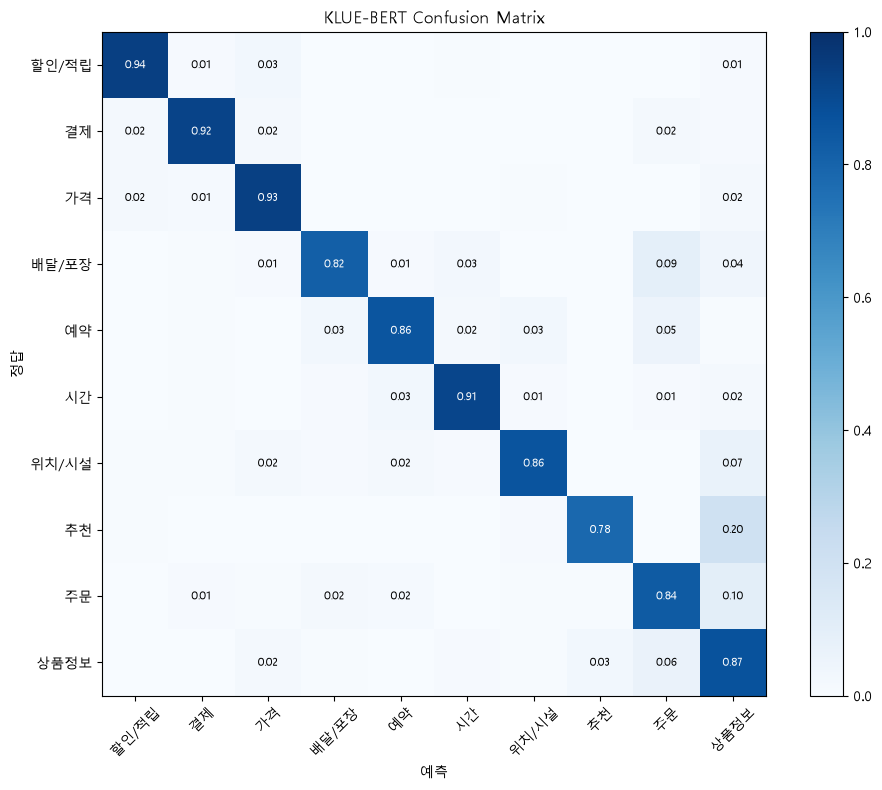

In [55]:
plt.figure(figsize=(10, 8))
plt.imshow(cm, cmap="Blues", vmin=0, vmax=1)
plt.colorbar()
for i in range(NUM_LABELS):
    for j in range(NUM_LABELS):
        if cm[i, j] >= 0.01:
            plt.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                     color="white" if cm[i, j] > 0.5 else "black")
plt.xticks(range(NUM_LABELS), INTENTS, rotation=45)
plt.yticks(range(NUM_LABELS), INTENTS)
plt.title("KLUE-BERT Confusion Matrix")
plt.xlabel("예측")
plt.ylabel("정답")
plt.tight_layout()
plt.show()

# **새로운 문장을 직접 입력하여 예측**

In [56]:
pipe = pipeline(
    task="text-classification",
    model=loaded_model,
    tokenizer=tokenizer,
    device=DEVICE,
    truncation=True,
    max_length=MAX_LEN,
    function_to_apply="softmax",
    top_k=None
)

In [57]:
print(pipe("오늘 날씨가 정말 좋다"))

[[{'label': 'LABEL_9', 'score': 0.43486133217811584}, {'label': 'LABEL_5', 'score': 0.19119451940059662}, {'label': 'LABEL_6', 'score': 0.12520354986190796}, {'label': 'LABEL_8', 'score': 0.11271461844444275}, {'label': 'LABEL_4', 'score': 0.04805028811097145}, {'label': 'LABEL_1', 'score': 0.0283043272793293}, {'label': 'LABEL_7', 'score': 0.025728877633810043}, {'label': 'LABEL_3', 'score': 0.014773881062865257}, {'label': 'LABEL_2', 'score': 0.013237608596682549}, {'label': 'LABEL_0', 'score': 0.0059310575015842915}]]


In [58]:
print(loaded_model.config.num_labels)
print(loaded_model.config.id2label)
print(loaded_model.config.problem_type)

10
{0: 'LABEL_0', 1: 'LABEL_1', 2: 'LABEL_2', 3: 'LABEL_3', 4: 'LABEL_4', 5: 'LABEL_5', 6: 'LABEL_6', 7: 'LABEL_7', 8: 'LABEL_8', 9: 'LABEL_9'}
single_label_classification


In [59]:
label_dict = {
    "LABEL_0": "할인/적립",
    "LABEL_1": "결제",
    "LABEL_2": "가격",
    "LABEL_3": "배달/포장",
    "LABEL_4": "예약",
    "LABEL_5": "시간",
    "LABEL_6": "위치/시설",
    "LABEL_7": "추천",
    "LABEL_8": "주문",
    "LABEL_9": "상품정보",
}

In [60]:
def prediction(text):
    results = pipe(text)
    if results and isinstance(results[0], list):
        results = results[0]

    # top_k=None이면 점수가 높은 순서로 정렬되어 나옴
    first, second = results[0], results[1]
    first_label = label_dict.get(first['label'], first['label'])
    second_label = label_dict.get(second['label'], second['label'])
    print(f"{text:<30} | 1등: {first_label}({first['score']:.2f}) | 2등: {second_label}({second['score']:.2f})")

In [62]:
examples = [
    "이 메뉴 얼마예요?",
    "통신사 할인 되나요?",
    "카드로 계산할게요",
    "아이스 아메리카노 두 잔 주세요",
    "팝콘 큰 거 하나랑 콜라 두 개 주세요",
    "일요일에도 진료하나요?",
    "엘리베이터는 어디에 있어요?",
    "배달비는 얼마예요?",
    "화장실 비밀번호가 뭐예요?",
    "사장님 혹시 MBTI가 뭐예요?",
]

for text in examples:
    prediction(text)

이 메뉴 얼마예요?                     | 1등: 가격(0.99) | 2등: 상품정보(0.00)
통신사 할인 되나요?                    | 1등: 할인/적립(0.99) | 2등: 가격(0.01)
카드로 계산할게요                      | 1등: 결제(0.99) | 2등: 주문(0.00)
아이스 아메리카노 두 잔 주세요              | 1등: 주문(0.99) | 2등: 결제(0.00)
팝콘 큰 거 하나랑 콜라 두 개 주세요          | 1등: 주문(0.99) | 2등: 배달/포장(0.01)
일요일에도 진료하나요?                   | 1등: 시간(0.99) | 2등: 예약(0.00)
엘리베이터는 어디에 있어요?                | 1등: 위치/시설(1.00) | 2등: 가격(0.00)
배달비는 얼마예요?                     | 1등: 가격(0.99) | 2등: 배달/포장(0.00)
화장실 비밀번호가 뭐예요?                 | 1등: 위치/시설(0.99) | 2등: 예약(0.00)
사장님 혹시 MBTI가 뭐예요?              | 1등: 상품정보(0.96) | 2등: 추천(0.03)
